# 04 — Transformer fine-tuning (Task D)

**Project:** Irony detection in tweets — TweetEval `irony` (SemEval-2018 Task 3)
**Goal of this notebook:** fine-tune a pre-trained transformer (BERT family) to classify tweets as **ironic (1)** or **not ironic (0)**, and compare it with the classical models (TF-IDF + NB / LogReg / SVM / RF / KNN) of the other notebooks.
**Author:** Mohamed Chaker Iben Hadj Amor
**Tools:** Python 3.12 · PyTorch (CUDA, RTX 5060 Ti) · Hugging Face Transformers & Datasets · pandas · scikit-learn

**Why a transformer?** TF-IDF models only count words: they lose word order and context. Irony lives precisely in the *contrast* between the words and the situation ("I *love* waiting 2 hours at the bank"). A transformer is pre-trained on billions of sentences and reads each word **in context**, so it should capture this contrast better.

**Plan**
1. Setup and GPU check
2. Loading the data
3. Data quality: corrupted rows
4. Hugging Face dataset format
5. Tokenization
6. Model, metrics and training (DistilBERT)
7. Results so far and next steps

## 1. Setup and GPU check

The first cell lets the notebook find the shared `src/` folder (one level up). The imports from `src/` are commented out for now: those files are written by other team members and are still empty.

Fine-tuning a transformer is heavy computation, so we first make sure **PyTorch can use the NVIDIA GPU**. Checking `torch.cuda.is_available()` is not enough: we also multiply two random 1000×1000 matrices **on the GPU**, which proves the GPU really computes.

**Sanity check of the result:** each entry of `x @ x` is a sum of 1000 products of two random numbers in [0, 1). Their average is 0.5 × 0.5 = 0.25, so each entry ≈ 250, and the sum of the 1,000,000 entries ≈ **250,000,000** — which is what we get.

In [1]:
import sys
sys.path.append("..")

#from src.config import *
#from src.data import load_split
#from src.cleaning import clean_text
#from src.evaluate import evaluate, save_results

In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0))

x = torch.rand(1000, 1000, device="cuda")
y = x @ x
print("Result:", y.sum().item())

PyTorch version: 2.15.0+cu132
CUDA available: True
GPU name: NVIDIA GeForce RTX 5060 Ti
Result: 249688944.0


## 2. Loading the data

The official TweetEval files store **text and labels in separate files**, one tweet per line: line *N* of `train_text.txt` goes with line *N* of `train_labels.txt`.

Choices made in `load_raw_split()`:
- **Read line by line, not with `pd.read_csv`**: hundreds of tweets contain commas and quotes, which `read_csv` would interpret as column separators and break the tweets apart.
- **`encoding="utf-8"`**: tweets contain emojis and special characters.
- **`.splitlines()`**: splits on line breaks without creating an empty extra row at the end of the file.
- **`assert`**: if a text file and its labels file ever had different lengths, every tweet after the mismatch would silently get the wrong label. The assert turns this into a clear error.

We check that we get the official sizes: **2862 / 955 / 784** tweets.

In [3]:
import pandas as pd

DATA_DIR = "../data/raw"

def load_raw_split(split):
    """Read one split ("train", "val" or "test") of TweetEval irony into a DataFrame."""
    with open(f"{DATA_DIR}/{split}_text.txt", encoding="utf-8") as f:
        texts = f.read().splitlines()

    with open(f"{DATA_DIR}/{split}_labels.txt", encoding="utf-8") as f:
        labels = [int(line) for line in f.read().splitlines()]

    assert len(texts) == len(labels), f"{split}: {len(texts)} texts but {len(labels)} labels"

    return pd.DataFrame({"text": texts, "label": labels})


train_df = load_raw_split("train")
val_df = load_raw_split("val")
test_df = load_raw_split("test")

print("train:", train_df.shape)
print("val:  ", val_df.shape)
print("test: ", test_df.shape)

train: (2862, 2)
val:   (955, 2)
test:  (784, 2)


In [4]:
train_df.head()

,text,label
0,seeing ppl walking w/ crutches makes me really...,1
1,"look for the girl with the broken smile, ask h...",0
2,Now I remember why I buy books online @user #s...,1
3,@user @user So is he banded from wearing the c...,1
4,Just found out there are Etch A Sketch apps. ...,1


## 3. Data quality: corrupted rows in the training set

Looking at the data before training, we noticed user mentions are already anonymized as `@user` and hashtags are kept.

While measuring tweet lengths, we found that the longest training "tweet" was in fact **about ten tweets merged into one line**, containing pieces of the original competition file: tweet IDs and **their own labels**, separated by tab characters (`\t`). Such a row has a single label while containing both ironic and non-ironic tweets, so **its label is unreliable**.

Searching all splits for tab characters:

| Split | Corrupted rows |
|---|---|
| train | **3** (1000, 329 and 249 characters long) |
| validation | 0 |
| test | 0 |

We **remove these 3 rows from the training set only** (2862 → **2859**). This is 0.1% of the data, so it doesn't change the class balance. The test set is clean and is never modified.

`reset_index(drop=True)` renumbers the rows after the removal; without it, the conversion to the Hugging Face format would add a useless extra index column.

In [5]:
corrupted = train_df["text"].str.contains("\t")

print("Corrupted rows found:", corrupted.sum())
print(train_df.loc[corrupted, "text"].str.len())

train_df = train_df[~corrupted].reset_index(drop=True)
print("train after removal:", train_df.shape)

Corrupted rows found: 3
1295    1000
1753     329
2773     249
Name: text, dtype: int64
train after removal: (2859, 2)


### 3.2 A hidden label leak: extra spaces

The ironic tweets were collected with the hashtags `#not`, `#sarcasm` and `#irony`, which the dataset authors deleted from the text afterwards. Deleting a word but not the space around it leaves **extra spaces**, typically at the end of the tweet. Non-ironic tweets were never edited, so they rarely have them.

This is invisible to the eye but very visible to some models: RoBERTa's tokenizer encodes spaces as tokens, so a model can learn *"double space at the end → ironic"* instead of learning irony. DistilBERT's tokenizer (like TF-IDF) ignores whitespace, which is why it was not affected.

We measure it in each split, then **normalize the whitespace** (one single space between words, none at the ends) in all three splits. This only changes spaces, never words, punctuation, capitals or emojis.

In [6]:
for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    share = df.groupby("label")["text"].apply(lambda s: s.str.endswith("  ").mean() * 100).round(1)
    print(f"{name:10} | ends with 2+ spaces -> non_irony: {share[0]:5.1f}%   irony: {share[1]:5.1f}%")

for df in (train_df, val_df, test_df):
    df["text"] = df["text"].str.split().str.join(" ")

print("\nAfter normalization, tweets ending with a space:",
      sum(df["text"].str.endswith(" ").sum() for df in (train_df, val_df, test_df)))

train      | ends with 2+ spaces -> non_irony:   3.3%   irony:  63.7%
validation | ends with 2+ spaces -> non_irony:   2.6%   irony:  56.6%
test       | ends with 2+ spaces -> non_irony:   0.0%   irony:   0.0%

After normalization, tweets ending with a space: 0


## 4. Hugging Face dataset format

The tokenizer and the `Trainer` work on Hugging Face `Dataset` objects, not on pandas DataFrames. We convert each split and group the three of them in a `DatasetDict`, so that later **one** `.map()` call can tokenize all splits at once. The split is named `validation`, following the Hugging Face convention.

The first training example already shows **verbal irony**: *"really excited for the next 3 weeks"* — said by someone on crutches. Positive words, negative situation, label 1.

In [7]:
from datasets import Dataset, DatasetDict

ds = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "validation": Dataset.from_pandas(val_df),
    "test": Dataset.from_pandas(test_df),
})

print(ds)
print(ds["train"][0])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 2859
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 955
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 784
    })
})
{'text': 'seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life', 'label': 1}


## 5. Tokenization

A neural network only works with numbers. The **tokenizer** converts each tweet into a list of **token IDs**:

`"really excited for my crutches"` → `["really", "excited", "for", "my", "crut", "##ches"]` → `[2428, 7568, ...]`

Key points:
- Tokens are often **pieces of words** (subwords): rare words are split into known pieces, so the model never meets a completely unknown word.
- **Each model has its own tokenizer**, and we must use the one it was pre-trained with — otherwise the IDs mean nothing to the model.
- The tokenizer adds **special tokens** (`[CLS]` at the start, `[SEP]` at the end for BERT models).
- The **attention mask** marks real tokens (1) versus padding (0).

We start with **DistilBERT** (`distilbert-base-uncased`), a smaller, faster version of BERT, to build and debug the full pipeline.

In [8]:
from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

example = ds["train"][0]["text"]
encoded = tokenizer(example)

print("Tweet:    ", example)
print("input_ids:", encoded["input_ids"])
print("tokens:   ", tokenizer.convert_ids_to_tokens(encoded["input_ids"]))
print("attention:", encoded["attention_mask"])

Tweet:     seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life
input_ids: [101, 3773, 4903, 2140, 3788, 1059, 1013, 13675, 4904, 8376, 3084, 2033, 2428, 7568, 2005, 1996, 2279, 1017, 3134, 1997, 2026, 2166, 102]
tokens:    ['[CLS]', 'seeing', 'pp', '##l', 'walking', 'w', '/', 'cr', '##ut', '##ches', 'makes', 'me', 'really', 'excited', 'for', 'the', 'next', '3', 'weeks', 'of', 'my', 'life', '[SEP]']
attention: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


### 5.1 Does the tokenizer keep the irony signals?

We tokenize a sarcastic sentence with two tokenizers:

| Tokenizer | Result for `"Oh GREAT, another Monday 🙂"` |
|---|---|
| DistilBERT (uncased) | `oh`, `great`, …, **`[UNK]`** |
| RoBERTa | `Oh`, `ĠGREAT`, …, **`ĠðŁĻĤ`** |

- DistilBERT-**uncased** lowercases everything: **"GREAT" (shouting) becomes "great"** (neutral).
- It doesn't know the emoji and replaces it with **`[UNK]`** (unknown): the 🙂 is lost.
- RoBERTa **keeps the capitals**, and encodes the emoji as a real token (the strange characters are the emoji's bytes; `Ġ` marks a preceding space).

**Conclusion:** DistilBERT-uncased loses two irony signals. This is why our final model will come from the **RoBERTa family**; DistilBERT is kept as a baseline for comparison.

In [9]:
roberta_tokenizer = AutoTokenizer.from_pretrained("FacebookAI/roberta-base")

test_tweet = "Oh GREAT, another Monday 🙂"

for name, tok in [("DistilBERT", tokenizer), ("RoBERTa", roberta_tokenizer)]:
    ids = tok(test_tweet)["input_ids"]
    print(f"{name:10} -> {tok.convert_ids_to_tokens(ids)}")

DistilBERT -> ['[CLS]', 'oh', 'great', ',', 'another', 'monday', '[UNK]', '[SEP]']
RoBERTa    -> ['<s>', 'Oh', 'ĠGREAT', ',', 'Ġanother', 'ĠMonday', 'ĠðŁĻĤ', '</s>']


### 5.2 Choosing the maximum length

Every model has a maximum input length, and we need to choose `max_length`: too short cuts tweets, too long wastes memory and time. We **measure** the length in tokens of every training tweet instead of guessing:

| Statistic | Value |
|---|---|
| mean | ≈ 23 tokens |
| median | 22 |
| 99th percentile | 44 |
| max (after removing the corrupted rows) | 60 |

Before the corrupted rows were removed, the max was 294 — that outlier is how we found them. Note that the 99th percentile was 44 in both cases: **percentiles are robust to outliers, the max is not**.

We choose **`MAX_LENGTH = 64`**: it covers 100% of the training tweets and leaves some margin for other tokenizers. Also note that **characters ≠ tokens**: a short tweet containing shortened links (`t.co/Q2WB7riAvK`) produces many tokens, because random strings are split into many small pieces.

In [10]:
token_lengths = [len(tokenizer(text)["input_ids"]) for text in train_df["text"]]

lengths = pd.Series(token_lengths)
print(lengths.describe())
print("99th percentile:", lengths.quantile(0.99))

count    2859.000000
mean       22.730325
std         9.082953
min         3.000000
25%        15.000000
50%        22.000000
75%        30.000000
max        60.000000
dtype: float64
99th percentile: 44.0


In [11]:
print(train_df.loc[lengths.idxmax(), "text"])

@user Hey #Russia ! MAKE MONEY #TWEETING YET?||http://t.co/Q2WB7riAvK <-This #FOXNews Clip explains how||https://t.co/cpJZkEgNe7


### 5.3 Tokenizing the whole dataset

`.map()` applies the tokenizer to every tweet of every split. With `batched=True`, tweets are processed in chunks, which is much faster. Tweets longer than 64 tokens are truncated.

We **don't pad here**. Padding is done later, batch by batch (*dynamic padding*): each batch is only padded to the length of its own longest tweet (often ~30 tokens) instead of always 64.

The `token_type_ids` column is only useful for tasks with two sentences (e.g. question + answer); it is ignored here and dropped automatically by the `Trainer`.

In [12]:
MAX_LENGTH = 64

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_ds = ds.map(tokenize, batched=True)

print(tokenized_ds)
print(tokenized_ds["train"][0])

Map:   0%|          | 0/2859 [00:00<?, ? examples/s]

Map:   0%|          | 0/955 [00:00<?, ? examples/s]

Map:   0%|          | 0/784 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2859
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 955
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 784
    })
})
{'text': 'seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life', 'label': 1, 'input_ids': [101, 3773, 4903, 2140, 3788, 1059, 1013, 13675, 4904, 8376, 3084, 2033, 2428, 7568, 2005, 1996, 2279, 1017, 3134, 1997, 2026, 2166, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


## 6. Model, metrics and training

### 6.1 The model: pre-trained body + new classification head

`AutoModelForSequenceClassification` loads DistilBERT's **pre-trained body** (which already "knows" English) and adds a **new classification head** with **2 outputs** (one score per class).

The warning when loading is expected:
- **UNEXPECTED**: the weights of the head used during pre-training (guessing hidden words) — not needed for our task, so they are dropped.
- **MISSING**: our new head (`pre_classifier`, `classifier`), which starts **random** and is what fine-tuning will train.

The model has about **67 million parameters**; less than 1% of them belong to the new head. Fine-tuning reuses the pre-trained knowledge and adapts it to irony.

In [13]:
from transformers import AutoModelForSequenceClassification

id2label = {0: "non_irony", 1: "irony"}
label2id = {"non_irony": 0, "irony": 1}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
)

print(model.classifier)
print(f"Parameters: {model.num_parameters():,}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=2, bias=True)
Parameters: 66,955,010


### 6.2 Dynamic padding

The GPU processes tweets in batches, and a batch must be a rectangle: every tweet the same length. The **data collator** pads each batch to the length of its longest tweet with a padding token, and sets the attention mask to 0 on the padding so the model ignores it.

In [14]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

### 6.3 Evaluation metric

After each epoch, the model is scored on the **validation** set (never the test set). The model outputs two scores (*logits*) per tweet; `argmax` picks the class with the highest score.

We report **accuracy** and **macro-F1** — the main metric of the whole project, so that all models are compared the same way. Macro-F1 computes the F1 score for each class separately and averages them, so a model that ignores one class cannot get a good score.

In [15]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1_macro": f1_score(labels, predictions, average="macro"),
    }

### 6.4 Training settings

| Setting | Value | Why |
|---|---|---|
| learning rate | 2e-5 | Small steps, so the pre-trained knowledge is adapted, not destroyed |
| batch size | 16 (train) / 64 (eval) | ≈ 179 steps per epoch |
| epochs | 4 | Few: a small dataset overfits quickly |
| weight decay | 0.01 | Regularization against overfitting |
| evaluation / saving | every epoch | To follow validation scores and keep checkpoints |
| `load_best_model_at_end` | True, by macro-F1 | Keep the best epoch, not necessarily the last one |
| `fp16` | True | Mixed precision: faster on the GPU |
| seed | 42 | Reproducibility |

Checkpoints are saved in `models/`, which is excluded from Git (the files are too large for GitHub).

In [16]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="../models/distilbert-irony",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    num_train_epochs=4,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=1,
    fp16=True,
    seed=42,
    report_to="none",
)

### 6.5 Training

The `Trainer` runs the full loop: for each batch, predict → compute the loss → adjust the weights; after each epoch, evaluate on validation and save a checkpoint. Training takes about 35 seconds on the GPU.

In [17]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_ds["train"],
    eval_dataset=tokenized_ds["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.652975,0.621042,0.640838,0.629368
2,0.529936,0.622585,0.661780,0.659847
3,0.400578,0.651111,0.661780,0.660157
4,0.301130,0.714461,0.682723,0.682654


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=716, training_loss=0.47115483630302896, metrics={'train_runtime': 63.5362, 'train_samples_per_second': 179.992, 'train_steps_per_second': 11.269, 'total_flos': 115405235493564.0, 'train_loss': 0.47115483630302896, 'epoch': 4.0})

In [18]:
trainer.evaluate()

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.301130,0.714461,4,0.682723,0.682654


{'eval_loss': 0.7144610285758972,
 'eval_accuracy': 0.6827225130890052,
 'eval_f1_macro': 0.6826543134732499}

## 7. Results so far

**Validation results (DistilBERT, seed 42):**

| Epoch | Training loss | Validation loss | Accuracy | Macro-F1 |
|---|---|---|---|---|
| 1 | 0.653 | 0.621 | 0.641 | 0.629 |
| 2 | 0.530 | 0.623 | 0.662 | 0.660 |
| 3 | 0.401 | 0.651 | 0.662 | 0.660 |
| **4** | 0.301 | 0.714 | 0.683 | **0.683** |

**How to read it**
- The **training loss** decreases at every epoch: the model fits the training tweets better and better.
- The **validation loss** stops improving after epoch 1–2 and then increases: the model starts to **overfit** (it memorizes the training tweets and becomes overconfident on its mistakes). Macro-F1 still creeps up because F1 only counts right/wrong answers, whereas the loss also measures confidence.
- With `load_best_model_at_end`, the model kept is the one with the best validation macro-F1 (here epoch 4): `trainer.evaluate()` returns exactly its numbers.

**Best validation macro-F1: 0.683.** Accuracy and macro-F1 are almost equal, so the model doesn't neglect one of the two classes.

**Run-to-run variability:** running the same code with the same seed several times gave between 0.683 and 0.692 (GPU computations in mixed precision are not perfectly deterministic). Differences below ~0.01 between two single runs are therefore not meaningful: the final comparison will use the **mean ± standard deviation over 3 seeds**.

DistilBERT's tokenizer ignores whitespace, so it was never affected by the extra-spaces leak of section 3.2: its score is the same before and after the fix.

For reference, the best system of the SemEval-2018 competition reached F1 = 0.71.

## 8. Twitter-RoBERTa

We now switch to a model better suited to our data: **Twitter-RoBERTa** (`cardiffnlp/twitter-roberta-base`), a RoBERTa-base model further pre-trained on about 60 million tweets by the Cardiff NLP team (the authors of TweetEval).

| | DistilBERT (uncased) | Twitter-RoBERTa |
|---|---|---|
| Size | ~67M parameters (distilled) | ~125M parameters |
| Capitals ("GREAT") | lost (lowercased) | kept |
| Emojis | `[UNK]` | real tokens |
| Pre-trained on | books + Wikipedia | RoBERTa data, then tweets |

All training settings are kept **identical** to the DistilBERT run, so that the only thing that changes is the model.

### 8.1 Matching the model's input format

During its pre-training on tweets, user mentions were replaced by `@user` and links by `http`. We apply the same replacement so our tweets look like what the model saw. This is not cleaning: capitals, punctuation and emojis are kept.

In [19]:
def preprocess(text):
    words = []
    for word in text.split(" "):
        if word.startswith("@") and len(word) > 1:
            word = "@user"
        elif word.startswith("http"):
            word = "http"
        words.append(word)
    return " ".join(words)

print(preprocess("@SenRandPaul look at this http://t.co/Q2WB7riAvK lol"))

ds_tw = ds.map(lambda batch: {"text": [preprocess(t) for t in batch["text"]]}, batched=True)
print(ds_tw["train"][2]["text"])

@user look at this http lol


Map:   0%|          | 0/2859 [00:00<?, ? examples/s]

Map:   0%|          | 0/955 [00:00<?, ? examples/s]

Map:   0%|          | 0/784 [00:00<?, ? examples/s]

Now I remember why I buy books online @user #servicewithasmile


### 8.2 Tokenizer of Twitter-RoBERTa

Each model needs its own tokenizer. We re-check the token lengths with this tokenizer to make sure `MAX_LENGTH = 64` still covers the tweets, then tokenize all splits.

In [20]:
TW_MODEL_NAME = "cardiffnlp/twitter-roberta-base"
tw_tokenizer = AutoTokenizer.from_pretrained(TW_MODEL_NAME)

tw_lengths = pd.Series([len(tw_tokenizer(t)["input_ids"]) for t in ds_tw["train"]["text"]])
print("99th percentile:", tw_lengths.quantile(0.99), "| max:", tw_lengths.max())

def tw_tokenize(batch):
    return tw_tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tw_tokenized_ds = ds_tw.map(tw_tokenize, batched=True)
print(tw_tokenized_ds)

99th percentile: 43.42000000000007 | max: 81


Map:   0%|          | 0/2859 [00:00<?, ? examples/s]

Map:   0%|          | 0/955 [00:00<?, ? examples/s]

Map:   0%|          | 0/784 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 2859
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 955
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 784
    })
})


### 8.3 Training

Same structure and settings as the DistilBERT training (section 6). Only the model, its tokenizer (and therefore the padding collator and the tokenized data) and the output folder change. The metric function is the same, so the scores are directly comparable.

In [21]:
tw_model = AutoModelForSequenceClassification.from_pretrained(
    TW_MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
)

tw_collator = DataCollatorWithPadding(tokenizer=tw_tokenizer)

tw_args = TrainingArguments(
    output_dir="../models/twitter-roberta-irony",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    num_train_epochs=4,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=1,
    fp16=True,
    seed=42,
    report_to="none",
)

tw_trainer = Trainer(
    model=tw_model,
    args=tw_args,
    train_dataset=tw_tokenized_ds["train"],
    eval_dataset=tw_tokenized_ds["validation"],
    data_collator=tw_collator,
    compute_metrics=compute_metrics,
)

tw_trainer.train()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream 

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.632430,0.573864,0.700524,0.698460
2,0.443728,0.578540,0.723560,0.723553
3,0.273370,0.748118,0.723560,0.723050
4,0.161407,0.916148,0.740314,0.740266


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=716, training_loss=0.37773377136145225, metrics={'train_runtime': 194.6521, 'train_samples_per_second': 58.751, 'train_steps_per_second': 3.678, 'total_flos': 229081340348400.0, 'train_loss': 0.37773377136145225, 'epoch': 4.0})

### 8.4 What happened with this model (history)

In a first run, **before the whitespace normalization of section 3.2 existed**, Twitter-RoBERTa reached a validation macro-F1 of **0.92** — far above anything published on this dataset (best SemEval-2018 system: 0.71) and far above DistilBERT (0.69). Warning signs: 0.91 after a single epoch, and a validation loss *lower* than the training loss at epoch 1 (the model found unseen tweets easier than its own training tweets).

Our first hypothesis was **data contamination** (the model's 58M pre-training tweets could contain this dataset). To test it, we ran a control: the same architecture **without** Twitter pre-training (`roberta-base`, section 9). It *also* reached 0.92, so the Twitter pre-training was **not** the cause.

The real cause was the **extra-spaces leak** described in section 3.2: in the raw data, 64% of ironic training tweets end with two or more spaces versus 3.5% of non-ironic ones (57% vs 3% in validation, 0% in test). RoBERTa's tokenizer sees spaces; DistilBERT's does not. This also explains why the TweetEval authors saw this model's F1 drop by 13 points from validation to test: the test set never had its hashtags removed, so it has no extra spaces.

The scores shown in this section now come from the run **after** the fix.

## 9. Control experiment: `roberta-base` (no Twitter pre-training)

Same architecture as Twitter-RoBERTa, but pre-trained only on books, news and web text — it has never seen tweets in bulk.

| | Twitter-RoBERTa | roberta-base |
|---|---|---|
| Architecture | RoBERTa-base | RoBERTa-base (identical) |
| Keeps capitals and emojis | yes | yes |
| Pre-trained on tweets | yes | no |

Everything else is identical: same input text, same `MAX_LENGTH`, same training settings, same metric. Before the whitespace fix, this control also scored 0.92, which ruled out contamination and led us to the extra-spaces leak (section 3.2). After the fix, comparing the two models tells us how much the Twitter pre-training really helps.

In [22]:
RB_MODEL_NAME = "FacebookAI/roberta-base"
rb_tokenizer = AutoTokenizer.from_pretrained(RB_MODEL_NAME)

def rb_tokenize(batch):
    return rb_tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

rb_tokenized_ds = ds_tw.map(rb_tokenize, batched=True)
print(rb_tokenized_ds)

Map:   0%|          | 0/2859 [00:00<?, ? examples/s]

Map:   0%|          | 0/955 [00:00<?, ? examples/s]

Map:   0%|          | 0/784 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 2859
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 955
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 784
    })
})


In [23]:
rb_model = AutoModelForSequenceClassification.from_pretrained(
    RB_MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
)

rb_collator = DataCollatorWithPadding(tokenizer=rb_tokenizer)

rb_args = TrainingArguments(
    output_dir="../models/roberta-base-irony",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    num_train_epochs=4,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=1,
    fp16=True,
    seed=42,
    report_to="none",
)

rb_trainer = Trainer(
    model=rb_model,
    args=rb_args,
    train_dataset=rb_tokenized_ds["train"],
    eval_dataset=rb_tokenized_ds["validation"],
    data_collator=rb_collator,
    compute_metrics=compute_metrics,
)

rb_trainer.train()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.652605,0.621321,0.654450,0.652530
2,0.532227,0.588357,0.693194,0.693188
3,0.387680,0.644929,0.708901,0.706791
4,0.266545,0.725091,0.721466,0.721429


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=716, training_loss=0.4597640010897674, metrics={'train_runtime': 130.4132, 'train_samples_per_second': 87.69, 'train_steps_per_second': 5.49, 'total_flos': 229081340348400.0, 'train_loss': 0.4597640010897674, 'epoch': 4.0})

### 9.1 Results after the fix

**Twitter-RoBERTa (section 8):**

| Epoch | Training loss | Validation loss | Macro-F1 |
|---|---|---|---|
| 1 | 0.632 | 0.574 | 0.698 |
| 2 | 0.444 | 0.579 | 0.724 |
| 3 | 0.273 | 0.748 | 0.723 |
| **4** | 0.161 | 0.916 | **0.740** |

**roberta-base (section 9):**

| Epoch | Training loss | Validation loss | Macro-F1 |
|---|---|---|---|
| 1 | 0.653 | 0.621 | 0.653 |
| 2 | 0.532 | 0.588 | 0.693 |
| 3 | 0.388 | 0.645 | 0.707 |
| **4** | 0.267 | 0.725 | **0.721** |

**Comparison (validation macro-F1, one run each, seed 42):**

| Model | Keeps capitals and emojis | Pre-trained on tweets | Best val macro-F1 |
|---|---|---|---|
| DistilBERT (uncased) | no | no | 0.683 |
| roberta-base | yes | no | 0.721 |
| Twitter-RoBERTa | yes | yes | **0.740** |

**Observations**
- After the fix, all scores are realistic (0.68–0.74) and in line with published results on this dataset: the 0.92 was entirely caused by the extra-spaces leak.
- The ranking matches our tokenizer analysis (section 5.1): keeping capitals and emojis helps (+0.04 from DistilBERT to roberta-base), and pre-training on tweets helps a bit more (+0.02).
- Twitter-RoBERTa overfits quickly: its validation loss almost doubles between epochs 2 and 4 while macro-F1 keeps rising slightly — it becomes very confident, including on its mistakes.
- These are single runs, and differences of about 0.01–0.02 are close to the run-to-run noise. The next step (3 seeds per model) will tell whether the gaps are real.

## 10. Robustness: 3 seeds per model

A single fine-tuning run depends on randomness: the initial values of the new head, the order of the training batches, and small non-deterministic GPU computations. We saw that the same code can move by ±0.005–0.01 from one run to the next. The gaps between our models (0.683 / 0.721 / 0.740) are only a few points, so one run each is not enough to rank them.

We train **each model 3 times with 3 different seeds** (42, 43, 44) and report the **mean ± standard deviation** of the validation macro-F1. A gap is convincing only if it is clearly larger than the standard deviations.

`model_init` makes the `Trainer` build a **brand-new model** at the start of each run, so no run can continue the training of a previous one. Checkpoints are only temporary: they are deleted after each run to save disk space (RoBERTa checkpoints are ~0.5 GB each).

In [24]:
import shutil

SEEDS = [42, 43, 44]
TMP_DIR = "../models/tmp_seed_runs"

def run_seeds(model_name, tokenized, model_tokenizer):
    collator = DataCollatorWithPadding(tokenizer=model_tokenizer)
    scores = []

    for seed in SEEDS:
        def model_init():
            return AutoModelForSequenceClassification.from_pretrained(
                model_name, num_labels=2, id2label=id2label, label2id=label2id
            )

        args = TrainingArguments(
            output_dir=TMP_DIR,
            learning_rate=2e-5,
            per_device_train_batch_size=16,
            per_device_eval_batch_size=64,
            num_train_epochs=4,
            weight_decay=0.01,
            eval_strategy="epoch",
            save_strategy="epoch",
            logging_strategy="epoch",
            load_best_model_at_end=True,
            metric_for_best_model="f1_macro",
            greater_is_better=True,
            save_total_limit=1,
            save_only_model=True,
            fp16=True,
            seed=seed,
            report_to="none",
            disable_tqdm=True,
        )

        trainer = Trainer(
            model_init=model_init,
            args=args,
            train_dataset=tokenized["train"],
            eval_dataset=tokenized["validation"],
            data_collator=collator,
            compute_metrics=compute_metrics,
        )
        trainer.train()

        f1 = trainer.evaluate()["eval_f1_macro"]
        scores.append(f1)
        print(f"{model_name} | seed {seed} | best val macro-F1 = {f1:.4f}")

        shutil.rmtree(TMP_DIR, ignore_errors=True)

    return scores

Each call trains one model 3 times. Expected duration on the RTX 5060 Ti: ~2–3 minutes for DistilBERT, ~5 minutes for each RoBERTa model.

In [25]:
seed_results = {
    "DistilBERT (uncased)": run_seeds(MODEL_NAME, tokenized_ds, tokenizer),
    "roberta-base": run_seeds(RB_MODEL_NAME, rb_tokenized_ds, rb_tokenizer),
    "Twitter-RoBERTa": run_seeds(TW_MODEL_NAME, tw_tokenized_ds, tw_tokenizer),
}

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '0.6525', 'grad_norm': '4.591', 'learning_rate': '1.503e-05', 'epoch': '1'}
{'eval_loss': '0.6246', 'eval_accuracy': '0.6503', 'eval_f1_macro': '0.6413', 'eval_runtime': '0.198', 'eval_samples_per_second': '4824', 'eval_steps_per_second': '75.77', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (107 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.1581', 'grad_norm': '1.402', 'learning_rate': '2.793e-08', 'epoch': '4'}
{'eval_loss': '0.8663', 'eval_accuracy': '0.7403', 'eval_f1_macro': '0.7403', 'eval_runtime': '0.338', 'eval_samples_per_second': '2825', 'eval_steps_per_second': '44.37', 'epoch': '4'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '54.14', 'train_samples_per_second': '211.2', 'train_steps_per_second': '13.22', 'train_loss': '0.3714', 'epoch': '4'}
{'eval_loss': '0.7181', 'eval_accuracy': '0.7424', 'eval_f1_macro': '0.7422', 'eval_runtime': '0.5519', 'eval_samples_per_second': '1730', 'eval_steps_per_second': '27.18', 'epoch': '4'}
cardiffnlp/twitter-roberta-base | seed 44 | best val macro-F1 = 0.7422


In [26]:
summary = pd.DataFrame({
    name: {
        "seed 42": s[0],
        "seed 43": s[1],
        "seed 44": s[2],
        "mean": np.mean(s),
        "std": np.std(s, ddof=1),
    }
    for name, s in seed_results.items()
}).T.round(4)

summary

,seed 42,seed 43,seed 44,mean,std
DistilBERT (uncased),0.6806,0.6733,0.6730,0.6756,0.0043
roberta-base,0.7204,0.7162,0.7240,0.7202,0.0039
Twitter-RoBERTa,0.7484,0.7445,0.7422,0.7450,0.0031


### 10.1 Interpretation

| Model | Mean val macro-F1 | Std (3 seeds) |
|---|---|---|
| DistilBERT (uncased) | 0.676 | 0.004 |
| roberta-base | 0.720 | 0.004 |
| Twitter-RoBERTa | **0.745** | 0.003 |

- **Run-to-run noise is small:** changing only the seed moves the score by about 0.004.
- **Both gaps are much larger than that noise:** +0.045 from DistilBERT to roberta-base (≈10× the std), and +0.025 from roberta-base to Twitter-RoBERTa (≈6× the std). The three ranges do not overlap: the worst Twitter-RoBERTa run (0.742) beats the best roberta-base run (0.724).
- **So the ranking from section 9 is confirmed:** keeping capitals and emojis helps, and pre-training on tweets helps further.
- **Caveat:** for each run, the best epoch was picked on the validation set (`load_best_model_at_end`), so these validation scores are slightly optimistic. The unbiased number will come from the test set, used only once.

**Final model for Task D: Twitter-RoBERTa** (`cardiffnlp/twitter-roberta-base`).

## 11. Final evaluation on the test set

The final model is **Twitter-RoBERTa** (section 10). We use the model trained in section 8 (seed 42, best epoch on validation): `load_best_model_at_end=True` means `tw_trainer` already holds that best epoch, and the section 10 runs used their own separate trainers.

The test set is used **only once**, here. Every decision (model, epochs, settings) was made on the validation set, so the test score is the only unbiased estimate of performance on new tweets. Nothing is changed after this section.

### 11.1 Saving and reloading the final model

The weights (~500 MB) and the tokenizer are saved together: a model is useless without the exact tokenizer it was trained with. The `models/` folder is ignored by Git (`.gitignore`), because GitHub refuses files over 100 MB.

**Important for re-runs:** the model is saved only if the folder does not exist yet. All the test results below come from **this saved model**, not from `tw_trainer`. Because of small GPU randomness, re-training in section 8 gives a slightly different model each time; loading the saved one guarantees that "Restart & Run All" always reproduces exactly the same test numbers — the test set is evaluated with one single, fixed model.

In [27]:
import os

FINAL_DIR = "../models/twitter-roberta-irony-final"

if not os.path.exists(FINAL_DIR):
    tw_trainer.save_model(FINAL_DIR)        # weights of the best epoch + config.json (id2label, ...)
    tw_tokenizer.save_pretrained(FINAL_DIR) # the matching tokenizer, in the same folder
    print("Saved to", FINAL_DIR)
else:
    print("Final model already saved in", FINAL_DIR, "-> reusing it")

# Reload the fixed final model and wrap it in a Trainer used only for predictions
final_model = AutoModelForSequenceClassification.from_pretrained(FINAL_DIR)
final_trainer = Trainer(
    model=final_model,
    args=TrainingArguments(output_dir="../models/tmp_eval", per_device_eval_batch_size=64,
                           fp16=True, report_to="none"),
    data_collator=tw_collator,
)

Final model already saved in ../models/twitter-roberta-irony-final -> reusing it


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

### 11.2 Predictions on the official test set

The test tweets go through exactly the same preparation as training (`@user`/`http` replacement, Twitter-RoBERTa tokenizer), so we use `tw_tokenized_ds["test"]`.

Official test macro-F1: 0.7726

              precision    recall  f1-score   support

   non_irony      0.872     0.736     0.798       473
       irony      0.675     0.836     0.747       311

    accuracy                          0.776       784
   macro avg      0.774     0.786     0.773       784
weighted avg      0.794     0.776     0.778       784



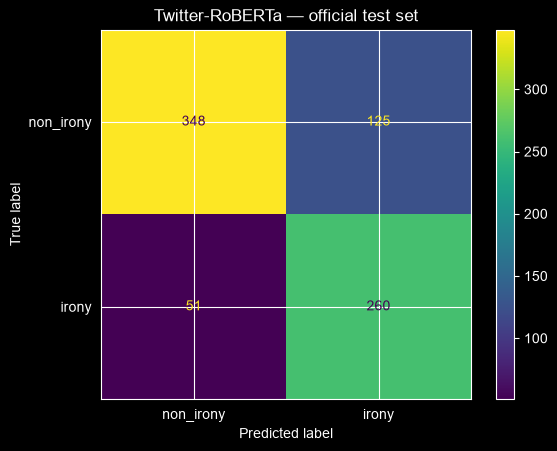

In [28]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

test_output = final_trainer.predict(tw_tokenized_ds["test"])

y_true_test = test_output.label_ids                           # correct answers
y_pred_test = np.argmax(test_output.predictions, axis=-1)     # biggest of the 2 scores -> 0 or 1

print("Official test macro-F1:", round(f1_score(y_true_test, y_pred_test, average="macro"), 4))
print()
print(classification_report(y_true_test, y_pred_test, target_names=["non_irony", "irony"], digits=3))

ConfusionMatrixDisplay.from_predictions(y_true_test, y_pred_test, display_labels=["non_irony", "irony"])
plt.title("Twitter-RoBERTa — official test set")
plt.show()

### 11.3 How much do the leftover hashtags help?

The dataset creators removed `#not`, `#irony` and `#sarcasm` from train and validation, but some are still present in the test set. These hashtags almost give away the answer, so the official test score may be inflated. We measure (a) how many test tweets contain them, (b) the accuracy on tweets with vs without them, and (c) the score on the whole test set after removing them.

`\b` in the pattern is a word boundary, so `#nothing` is not matched; `IGNORECASE` also catches `#NOT` or `#Sarcasm`.

In [29]:
import re

HASHTAG_RE = re.compile(r"#(?:not|irony|sarcasm)\b", flags=re.IGNORECASE)

# True/False per test tweet (same order as the predictions: the test set was never shuffled or filtered)
has_tag = test_df["text"].str.contains(HASHTAG_RE).to_numpy()

print(f"Test tweets with #not/#irony/#sarcasm: {has_tag.sum()} / {len(has_tag)}")
print("Share of ironic tweets among them:   ", round(y_true_test[has_tag].mean(), 3))
print("Share of ironic tweets among the rest:", round(y_true_test[~has_tag].mean(), 3))

Test tweets with #not/#irony/#sarcasm: 431 / 784
Share of ironic tweets among them:    0.722
Share of ironic tweets among the rest: 0.0


In [30]:
# The tweets WITHOUT a hashtag are all non-ironic (see the cell above), so macro-F1 makes no
# sense on that group (one class only). We compare accuracy per group instead.
acc_with = (y_pred_test[has_tag] == y_true_test[has_tag]).mean()
acc_without = (y_pred_test[~has_tag] == y_true_test[~has_tag]).mean()

print(f"Accuracy on tweets WITH a hashtag    (n = {has_tag.sum()}): {acc_with:.3f}")
print(f"Accuracy on tweets WITHOUT a hashtag (n = {(~has_tag).sum()}): {acc_without:.3f}")

Accuracy on tweets WITH a hashtag    (n = 431): 0.833
Accuracy on tweets WITHOUT a hashtag (n = 353): 0.705


Now we delete the hashtags from every test tweet and predict again. After deleting, the spaces are normalized again (same as section 3.2), otherwise the removal would leave double spaces — the exact leak we fixed. The labels do not change, only the text.

In [31]:
test_clean_df = test_df.copy()
test_clean_df["text"] = (
    test_clean_df["text"]
    .str.replace(HASHTAG_RE, "", regex=True)   # delete the hashtags
    .str.split()
    .str.join(" ")                             # back to single spaces
)

ds_test_clean = Dataset.from_pandas(test_clean_df)
ds_test_clean = ds_test_clean.map(lambda batch: {"text": [preprocess(t) for t in batch["text"]]}, batched=True)
tw_test_clean = ds_test_clean.map(tw_tokenize, batched=True)

clean_output = final_trainer.predict(tw_test_clean)
y_pred_clean = np.argmax(clean_output.predictions, axis=-1)

print("Test macro-F1 WITHOUT the hashtags:", round(f1_score(y_true_test, y_pred_clean, average="macro"), 4))
print(classification_report(y_true_test, y_pred_clean, target_names=["non_irony", "irony"], digits=3))

Map:   0%|          | 0/784 [00:00<?, ? examples/s]

Map:   0%|          | 0/784 [00:00<?, ? examples/s]

Test macro-F1 WITHOUT the hashtags: 0.7412
              precision    recall  f1-score   support

   non_irony      0.826     0.734     0.777       473
       irony      0.654     0.765     0.705       311

    accuracy                          0.746       784
   macro avg      0.740     0.749     0.741       784
weighted avg      0.758     0.746     0.749       784



### 11.4 Test results

| Test version | Score |
|---|---|
| Official test set — macro-F1 | **0.773** |
| — accuracy on tweets with a hashtag (n = 431) | 0.833 |
| — accuracy on tweets without a hashtag (n = 353, all non-ironic) | 0.705 |
| Test set with the hashtags removed — macro-F1 | **0.741** |
| *(reminder) validation, mean of 3 seeds* | *0.745* |

**Interpretation**
- **The test set is not built like train and validation.** Every ironic test tweet contains `#not`, `#irony` or `#sarcasm`, while all 353 tweets without one are non-ironic. In train and validation these hashtags were deleted, so the official test set contains a shortcut that the other splits do not.
- **The hashtags inflate the official score by about 0.03** (0.773 → 0.741). The model never saw these hashtags in our training data, but Twitter-RoBERTa was pre-trained on millions of tweets where `#not` and `#sarcasm` signal irony, so it still recognizes them.
- **The score without hashtags (0.741) matches the validation estimate (0.745 ± 0.003).** The model generalizes to new tweets as expected; we report **0.741** as our honest test score and 0.773 as the official one.
- **Main weakness: false irony.** About 30% of the non-ironic tweets without a hashtag are predicted ironic (accuracy 0.705 on that group), and irony recall (0.765–0.836) is higher than irony precision (0.65–0.68). The model tends to see irony where there is none. Section 12 looks at these errors in detail.

## 12. Error analysis

A score says *how often* the model is wrong, not *why*. Here we read the mistakes of the final model on the **test set without the hashtags** (the honest version from 11.3), and compare them with the best classical model, Logistic Regression.

For each tweet we also keep `p_irony`, the probability of irony given by the model. The logits (2 raw scores) are turned into probabilities with **softmax**, which makes them positive and sum to 1. A wrong answer with `p_irony` close to 0 or 1 is a **confident mistake**: those are the most interesting ones to read.

In [32]:
import torch

# Probability of the class "irony" for each test tweet (softmax over the 2 logits, keep column 1)
p_irony = torch.softmax(torch.tensor(clean_output.predictions), dim=-1)[:, 1].numpy()

analysis = pd.DataFrame({
    "text": test_clean_df["text"],
    "true": y_true_test,
    "pred": y_pred_clean,
    "p_irony": p_irony.round(3),
})

# TP = ironic & found, TN = not ironic & found, FP = false irony, FN = missed irony
analysis["result"] = np.select(
    [(analysis["true"] == 1) & (analysis["pred"] == 1),
     (analysis["true"] == 0) & (analysis["pred"] == 0),
     (analysis["true"] == 0) & (analysis["pred"] == 1)],
    ["TP", "TN", "FP"],
    default="FN",
)

print(analysis["result"].value_counts())

result
TN    347
TP    238
FP    126
FN     73
Name: count, dtype: int64


### 12.1 False irony (FP): non-ironic tweets predicted ironic

The 10 tweets the model was **most sure** were ironic, while they are not.

In [33]:
pd.set_option("display.max_colwidth", None)   # show the full tweet text

analysis[analysis["result"] == "FP"].sort_values("p_irony", ascending=False).head(10)[["text", "p_irony"]]

,text,p_irony
5,Corny jokes are my absolute favorite,0.998
90,You are taking your responsibilities so seriously today that i... More for Leo,0.998
216,Once again @user is re writing history re: #CubaEmbargo ! *primal scream* #tcot,0.998
700,Today was a very good day in Iceland.,0.998
197,Nice touch. All the bar staff in the ground wearing #saintsfc t shirts,0.997
71,Getting Final Jeopardy correct on Kids Jeopardy boosts my self-esteem,0.997
524,@user Ahem... yeah.. something like that ;) is one of the few things keeping sanity when facing RU propaganda. #CrazyIvan,0.997
204,@user his daughter is painting his toes! That is a parenting WIN in my book.,0.997
373,I wonder how many people who visit food banks have huge TVs or are drunks? #freedomofspeech #foodbanks,0.996
10,Most important thing I've learned in school,0.996


### 12.2 Missed irony (FN): ironic tweets predicted non-ironic

The 10 ironic tweets the model was **most sure** were not ironic.

In [34]:
analysis[analysis["result"] == "FN"].sort_values("p_irony").head(10)[["text", "p_irony"]]

,text,p_irony
4,So much at work mate 10/10 #boring 100% #dead mate full on #shit absolutely #sleeping mate can't handle the,0.004
274,"My dad's still gonna get me santa's gifts since it's my last year before 18, but I really don't know what to ask for...",0.004
613,"Few #relations are by #chance, few are by #choice and few are by #Facebook!!",0.004
91,@user @user @user @user @user we get it right for business the trickle down fairy will do the rest,0.005
498,08:01am on the dot and the buzzer rings #helloworld #sleepy #tired #nothanks,0.005
219,What to do with that old #motherboard you have laying around. #guitarpicks,0.006
267,I may or may not have put @user at the top of @user tree soon as he likes Christmas time...,0.006
682,How can u miss something u never had?||#randomthoughts #miss |http://t.co/G5jLy9IKqn,0.008
633,@user maybe you should grind the gym man #calling #you #fat,0.010
231,i just enjoy throwing up #hatethis #sick #wanna #go #to #school #for #once #take #me #away,0.010


### 12.3 Comparison with the classical model

To compare the *mistakes* (not only the scores), we rebuild the best classical model of notebook 02 with **exactly the same settings**: TF-IDF on words (1,2), `min_df=2`, Logistic Regression `C=3`, trained on Task A's cleaned text (`text_clean`). It is evaluated on the same test tweets with the hashtags removed, so both models face the same task.

*(Notebook 05 compares all the models officially; this is only a reference for the error analysis.)*

In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

proc_train = pd.read_csv("../data/processed/train.csv", keep_default_na=False)
proc_test = pd.read_csv("../data/processed/test.csv", keep_default_na=False)   # same order as test_df

logreg = Pipeline([
    ("tfidf", TfidfVectorizer(token_pattern=r"[\w']+|[^\w\s]", lowercase=False, ngram_range=(1, 2), min_df=2)),
    ("clf", LogisticRegression(C=3, max_iter=1000, random_state=42)),
])
logreg.fit(proc_train["text_clean"], proc_train["label"])

# Same hashtag removal + space normalization as for the transformer
test_text_lr = proc_test["text_clean"].str.replace(HASHTAG_RE, "", regex=True).str.split().str.join(" ")
y_pred_lr = logreg.predict(test_text_lr)

print("LogReg          — test macro-F1 (hashtags removed):", round(f1_score(y_true_test, y_pred_lr, average="macro"), 4))
print("Twitter-RoBERTa — test macro-F1 (hashtags removed):", round(f1_score(y_true_test, y_pred_clean, average="macro"), 4))

analysis["logreg_pred"] = y_pred_lr
rob_ok = analysis["pred"] == analysis["true"]
lr_ok = analysis["logreg_pred"] == analysis["true"]

pd.crosstab(rob_ok.rename("Twitter-RoBERTa correct"), lr_ok.rename("LogReg correct"), margins=True)

LogReg          — test macro-F1 (hashtags removed): 0.6604
Twitter-RoBERTa — test macro-F1 (hashtags removed): 0.7412


LogReg correct,False,True,All
Twitter-RoBERTa correct,,,
False,118,81,199
True,145,440,585
All,263,521,784


How to read the table: the diagonal is where both models agree (both right, or both wrong). The two other cells show the tweets where **only one** of them is right — that is where the transformer's understanding of context makes (or does not make) a difference.

Tweets that **only Twitter-RoBERTa** gets right:

In [36]:
analysis[rob_ok & ~lr_ok].sample(8, random_state=42)[["text", "true", "p_irony"]]

,text,true,p_irony
392,That moment when the ad plays flawlessly but the video keeps buffering #YouTube @user,1,0.977
757,"you seem super smart MT ""@GrannyMarried: @user @user ||#NO #BLEEDING happening in #WaterBoarding = it's #Torture""",1,0.989
144,@user Minky Wale tail fritter for price of a bijoux flat in Port Talbot.,0,0.010
121,Testing water temperatures #excitingtimes,1,0.998
262,@user @user Probably my favourite book. Couldn't put it down. 5Stars!,0,0.006
612,@user Things also go slowly when you are waiting for them especially!,0,0.156
679,Please snow let us get out of dance early,0,0.067
563,#tbt Dedicated to those days we DONT want to throwback to. Like this evil cold November day at...,0,0.089


Tweets that **only LogReg** gets right:

In [37]:
analysis[~rob_ok & lr_ok].sample(8, random_state=42)[["text", "true", "p_irony"]]

,text,true,p_irony
303,clashupdate,1,0.244
25,@user hmm... let me think about that,1,0.014
223,Never seen the gym so packed,0,0.958
304,@user Super Junior's Henry asks sasaeng fans to let him sleep|http://t.co/BhrEKEtMka Henry oppa >^<,0,0.607
197,Nice touch. All the bar staff in the ground wearing #saintsfc t shirts,0,0.997
285,@user @user @user Just wait till Cleveland comes again!,1,0.237
109,HAHAHAHA!! Oops.......I'm addicted to @user Tweets sooo FUNNY! You Got to follow him for #HILARIOUS #tweets #RT.,0,0.898
699,I have three exams today lets gooooo! #School #Swag,1,0.072


### 12.4 What the errors show

On the test set without hashtags, the model makes **126 false ironies (FP)** and **73 missed ironies (FN)**, against 347 TN and 238 TP: it errs mostly on the side of seeing irony.

**False irony — enthusiasm read as sarcasm.** The most confident FPs are short, very positive statements: *"Corny jokes are my absolute favorite"*, *"Today was a very good day in Iceland."*, *"Getting Final Jeopardy correct on Kids Jeopardy boosts my self-esteem"* (all at p ≥ 0.997). The model has learned that exaggerated positivity is a strong sign of irony — which is true in this dataset — but it cannot tell a sincere compliment from a sarcastic one without context. Several of these tweets could honestly be read as ironic by a human too: part of the "errors" are **ambiguous labels**, not only model mistakes.

**Missed irony — irony carried by hashtags or by the situation.** The most confident FNs (p ≤ 0.01) are of two kinds:
- tweets whose irony lives in **hashtags that contradict the text** (*"i just enjoy throwing up #hatethis #sick ..."*, *"08:01am on the dot and the buzzer rings #helloworld #sleepy #tired #nothanks"*), or **situational irony** that needs world knowledge (*"What to do with that old #motherboard ... #guitarpicks"*);
- tweets **damaged by our hashtag removal**: in *"So much #sarcasm at work mate..."* or *"#NOT GONNA WIN"*, the hashtag was a word of the sentence, so removing it leaves an incomplete text (*"So much at work mate..."*, *"GONNA WIN"*). The score without hashtags (0.741) is therefore a slightly **pessimistic** estimate, and the official score (0.773) an optimistic one: the true performance lies between the two.

**Twitter-RoBERTa vs LogReg (same 784 tweets):**

| | LogReg wrong | LogReg right |
|---|---|---|
| **Twitter-RoBERTa wrong** | 118 | 81 |
| **Twitter-RoBERTa right** | 145 | 440 |

- The transformer corrects **145** of LogReg's errors and introduces **81** new ones: a net gain of 64 tweets (+0.08 macro-F1).
- Where only Twitter-RoBERTa is right, the irony lies in the **contrast between two parts of the tweet** (*"the ad plays flawlessly but the video keeps buffering"*), or a positive tweet is correctly kept **sincere** (*"Probably my favourite book. Couldn't put it down. 5Stars!"*) where LogReg only sees the word *favourite*. This needs word order and context — exactly what a bag of words throws away.
- Where only LogReg is right, Twitter-RoBERTa again over-reads enthusiasm (*"Never seen the gym so packed"*, *"HAHAHAHA!! ... sooo FUNNY!"*).
- **118 tweets (15%) are missed by both models**: a hard core of tweets where irony depends on information that is not in the text.

## 13. Saving the results for the comparison notebook

Every model of the project writes its scores to `results/metrics_<task>.csv` with the **same columns** (`model, split, accuracy, precision, recall, f1, f1_macro, params`), so notebook 05 can put all models in one table. `precision`, `recall` and `f1` are for the class *irony*; `f1_macro` is the main metric.

We write three rows for the final model: validation, official test, and test with the hashtags removed.

In [38]:
from sklearn.metrics import precision_score, recall_score

PARAMS = "cardiffnlp/twitter-roberta-base; lr=2e-5; 4 epochs (best on val); batch 16; max_length 64; seed 42"

def metrics_row(split, y_true, y_pred):
    return {
        "model": "Twitter-RoBERTa",
        "split": split,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "params": PARAMS,
    }

# Validation predictions of the same saved model
val_output = final_trainer.predict(tw_tokenized_ds["validation"])
y_pred_val = np.argmax(val_output.predictions, axis=-1)

metrics_D = pd.DataFrame([
    metrics_row("validation", val_output.label_ids, y_pred_val),
    metrics_row("test", y_true_test, y_pred_test),
    metrics_row("test_no_hashtags", y_true_test, y_pred_clean),
])
metrics_D.to_csv("../results/metrics_D.csv", index=False)

metrics_D.drop(columns="params").round(4)

,model,split,accuracy,precision,recall,f1,f1_macro
0,Twitter-RoBERTa,validation,0.7403,0.7140,0.7610,0.7367,0.7403
1,Twitter-RoBERTa,test,0.7755,0.6753,0.8360,0.7471,0.7726
2,Twitter-RoBERTa,test_no_hashtags,0.7462,0.6538,0.7653,0.7052,0.7412


## 14. Conclusion

**Final model:** Twitter-RoBERTa (`cardiffnlp/twitter-roberta-base`), fine-tuned 4 epochs on the raw tweets (mentions → `@user`, links → `http`).

| | Macro-F1 |
|---|---|
| Validation (mean of 3 seeds) | 0.745 ± 0.003 |
| Test — official | 0.773 |
| **Test — hashtags `#not`/`#irony`/`#sarcasm` removed** | **0.741** |
| LogReg on the same test, for reference | 0.660 |

**What we learned**
1. **Check the data before trusting a score.** Our first Twitter-RoBERTa reached 0.92: the cause was not the model but a **leak** — the dataset creators deleted the irony hashtags but left the extra spaces, and RoBERTa's tokenizer sees spaces. Normalizing whitespace (section 3.2) brought scores back to realistic values. The test set has a similar trap: every ironic tweet still contains one of these hashtags, which inflates the official score by about 0.03.
2. **One run is not a result.** Repeating training with 3 seeds showed a run-to-run noise of ~0.004, much smaller than the gaps between models: the ranking DistilBERT (0.676) < roberta-base (0.720) < Twitter-RoBERTa (0.745) is real.
3. **Each step of the ranking has a reason.** Keeping capitals and emojis (RoBERTa's cased, byte-level tokenizer) adds about +0.04; pre-training on tweets adds about +0.025.
4. **Validation predicted the test well** (0.745 vs 0.741): choosing the model on validation and touching the test only once gave an honest estimate.
5. **Context is what the transformer adds**, compared with TF-IDF models: it handles contrasts inside a tweet and sincere positive tweets better, but still over-reads enthusiasm as sarcasm and misses irony that needs outside knowledge.

**Limits and next steps**
- Small dataset (2,859 training tweets) and some ambiguous labels: part of the remaining errors cannot be fixed by the model alone.
- The model overfits quickly (validation loss rises after epoch 2); more data or stronger regularization would help more than more epochs.
- Possible improvements: averaging the 3 seed models (ensemble), or adding the tweet's context (the conversation it replies to).